# **Aplicação: Problema da Mochila**

*Situação*

Um caminhão pode transportar até 15 kg.

Existem diversos itens disponíveis.

O objetivo é:

- maximizar o valor transportado;
- sem ultrapassar 15 kg.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 218.3/218.3 kB 6.3 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/pygad/utils/validation.py:1914: UserWarning: Use the 'save_best_solutions' parameter with caution as it may cause memory overflow when either the number of generations or number of genes is large.
  warnings.warn("Use the 'save_best_solutions' parameter with caution as it may cause memory overflow when either the number of generations or number of genes is large.")


MELHOR SOLUÇÃO ENCONTRADA
Item 1 | Peso=2 kg | Valor=6
Item 5 | Peso=6 kg | Valor=18
Item 6 | Peso=7 kg | Valor=22

Peso total: 15
Valor total: 46


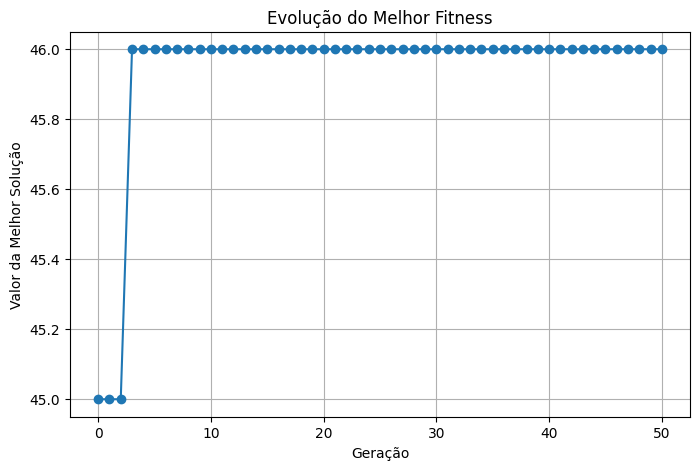

In [ ]:
# ==========================================================
# ALGORITMO GENÉTICO - PROBLEMA DA MOCHILA
# ==========================================================
#
# Objetivo:
#
# Escolher os itens mais valiosos sem ultrapassar
# a capacidade máxima da mochila.
#
# ==========================================================

!pip install pygad

import pygad
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# DADOS DO PROBLEMA
# ==========================================================
#
# Cada item possui:
#
# peso
# valor
#
# ==========================================================

pesos = [2, 3, 5, 4, 6, 7]

valores = [6, 8, 15, 10, 18, 22]

capacidade_mochila = 15

# ==========================================================
# INTERPRETAÇÃO DO CROMOSSOMO
# ==========================================================
#
# Cada gene pode assumir:
#
# 0 = item não escolhido
# 1 = item escolhido
#
# Exemplo:
#
# [1,0,1,0,0,1]
#
# significa:
#
# item 1 escolhido
# item 2 não escolhido
# item 3 escolhido
# item 4 não escolhido
# item 5 não escolhido
# item 6 escolhido
#
# ==========================================================


# ==========================================================
# FUNÇÃO FITNESS
# ==========================================================
#
# O AG tenta MAXIMIZAR o fitness.
#
# Neste problema:
#
# fitness = valor total dos itens
#
# Porém:
#
# Se ultrapassar o peso máximo,
# recebe penalização.
#
# ==========================================================

def fitness_func(ga_instance, solution, solution_idx):

    peso_total = 0
    valor_total = 0

    for gene, peso, valor in zip(solution, pesos, valores):

        if gene == 1:
            peso_total += peso
            valor_total += valor

    # Penalização
    if peso_total > capacidade_mochila:
        return 0

    return valor_total


# ==========================================================
# CONFIGURAÇÃO DO ALGORITMO GENÉTICO
# ==========================================================

ga_instance = pygad.GA(

    num_generations=50,

    sol_per_pop=30,

    num_parents_mating=10,

    num_genes=len(pesos),

    gene_space=[0, 1],

    fitness_func=fitness_func,

    parent_selection_type="rws",

    crossover_type="single_point",

    mutation_type="random",

    mutation_percent_genes=20,

    save_best_solutions=True
)

# ==========================================================
# EXECUÇÃO
# ==========================================================

ga_instance.run()

# ==========================================================
# MELHOR SOLUÇÃO
# ==========================================================

solution, fitness, idx = ga_instance.best_solution()

print("=" * 50)
print("MELHOR SOLUÇÃO ENCONTRADA")
print("=" * 50)

peso_total = 0
valor_total = 0

for i, gene in enumerate(solution):

    if gene == 1:

        peso_total += pesos[i]
        valor_total += valores[i]

        print(
            f"Item {i+1} | Peso={pesos[i]} kg | Valor={valores[i]}"
        )

print("\nPeso total:", peso_total)
print("Valor total:", valor_total)

# ==========================================================
# EVOLUÇÃO DA SOLUÇÃO
# ==========================================================

plt.figure(figsize=(8,5))

plt.plot(
    ga_instance.best_solutions_fitness,
    marker='o'
)

plt.title("Evolução do Melhor Fitness")

plt.xlabel("Geração")

plt.ylabel("Valor da Melhor Solução")

plt.grid(True)

plt.show()